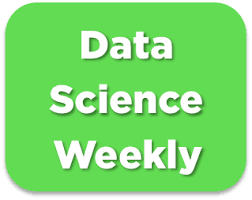

# Challenge : predict conversions 🏆🏆

This is the template that shows the different steps of the challenge. In this notebook, all the training/predictions steps are implemented for a very basic model (logistic regression with only one variable). Please use this template and feel free to change the preprocessing/training steps to get the model with the best f1-score ! May the force be with you 🧨🧨  

**For a detailed description of this project, please refer to *02-Conversion_rate_challenge.ipynb*.**

# Import libraries

In [28]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, confusion_matrix

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go
import plotly.io as pio
# setting Jedha color palette as default
"""pio.templates["jedha"] = go.layout.Template(
    layout_colorway=["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]
)
pio.templates.default = "jedha"
pio.renderers.default = "svg" # to be replaced by "iframe" if working on JULIE"""
# Définition d'un template personnalisé avec une palette de couleurs spécifique
custom_colorway = ["#4B9AC7", "#4BE8E0", "#9DD4F3", "#97FBF6", "#2A7FAF", "#23B1AB", "#0E3449", "#015955"]

custom_template = go.layout.Template(layout_colorway=custom_colorway)

from IPython.display import display

# Read file with labels

In [2]:
data = pd.read_csv('conversion_data_train.csv')
print('Set with labels (our train+test) :', data.shape)

Set with labels (our train+test) : (284580, 6)


In [3]:
data.head(20)

,country,age,new_user,source,total_pages_visited,converted
0,China,22,1,Direct,2,0
1,UK,21,1,Ads,3,0
2,Germany,20,0,Seo,14,1
3,US,23,1,Seo,3,0
4,US,28,1,Direct,3,0
5,US,29,0,Seo,7,0
6,US,30,1,Direct,4,0
7,UK,38,1,Ads,2,0
8,UK,26,1,Seo,4,0
9,UK,31,0,Seo,5,0


# Explore dataset

In [13]:
data.describe(include='all')

,country,age,new_user,source,total_pages_visited,converted
count,284580,284580.000000,284580.000000,284580,284580.000000,284580.000000
unique,4,NaN,NaN,3,NaN,NaN
top,US,NaN,NaN,Seo,NaN,NaN
freq,160124,NaN,NaN,139477,NaN,NaN
mean,NaN,30.564203,0.685452,NaN,4.873252,0.032258
std,NaN,8.266789,0.464336,NaN,3.341995,0.176685
min,NaN,17.000000,0.000000,NaN,1.000000,0.000000
25%,NaN,24.000000,0.000000,NaN,2.000000,0.000000
50%,NaN,30.000000,1.000000,NaN,4.000000,0.000000
75%,NaN,36.000000,1.000000,NaN,7.000000,0.000000


In [8]:
# outliers : age 123 ; total pages visited 29 avg 4.87 ; 3qt=7 3sigma = 14? 
data [data.age >70 ]    # 2 outliers age >100 y w/ conversion ; 2 louches source direct age>75 


,country,age,new_user,source,total_pages_visited,converted
11331,UK,111,0,Ads,10,1
104541,US,72,1,Direct,4,0
175251,US,73,1,Seo,5,0
230590,US,79,1,Direct,1,0
233196,Germany,123,0,Seo,15,1
268311,US,77,0,Direct,4,0


In [12]:
data[data.total_pages_visited>25]  #looks good

,country,age,new_user,source,total_pages_visited,converted
9390,Germany,24,0,Seo,26,1
36590,China,22,0,Direct,26,1
58515,US,37,1,Ads,26,1
68329,US,22,0,Ads,27,1
76137,UK,17,1,Seo,27,1
80293,US,25,0,Ads,26,1
84783,Germany,22,1,Seo,27,1
87376,US,29,0,Ads,26,1
88265,US,24,0,Seo,27,1
89111,UK,19,0,Seo,26,1


In [38]:
25/284580

8.78487595755148e-05

In [39]:
# remove outliers : 
data = data [data.age <=70 ] # suppr 6 
data = data[data.total_pages_visited<=25]   # 25 

In [112]:
# The dataset is quite big : you must create a sample of the dataset before making any visualizations !
data_sample = data.sample(10000)

In [17]:
features_list = ['country', 'age','new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]
num_features = [features_list[i] for i in numeric_indices]
cat_features = [features_list[i] for i in categorical_indices]


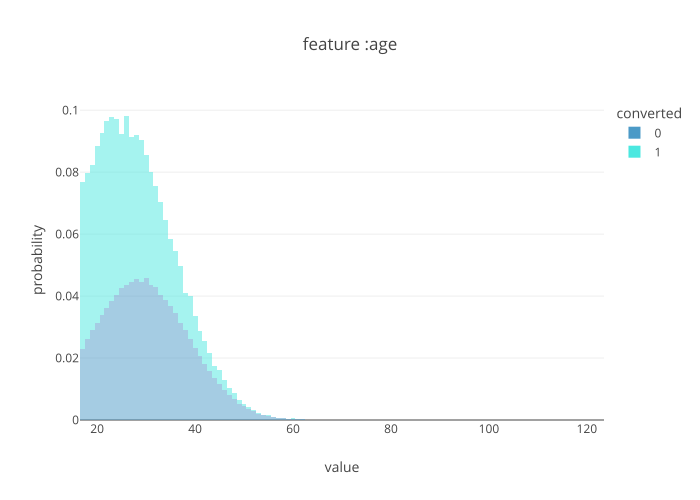

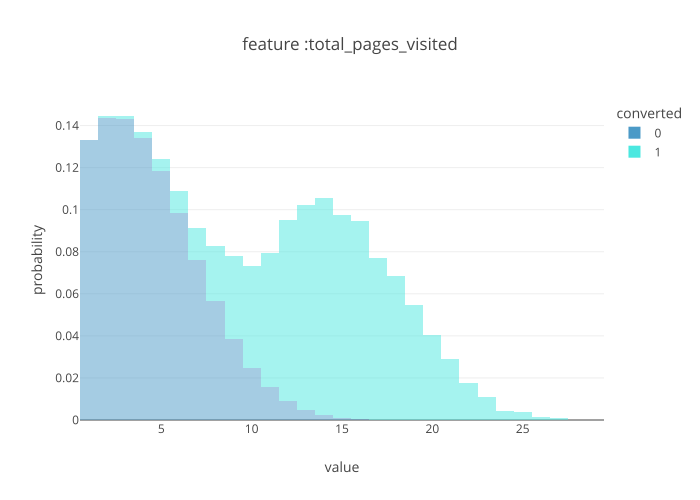

In [ ]:

for i in range(len(num_features)):
    fig = px.histogram(data, x=[num_features[i]],
                       color='converted',
                       title=f"feature :{num_features[i]}",
                       histnorm='probability',opacity=0.5)
    fig.show()

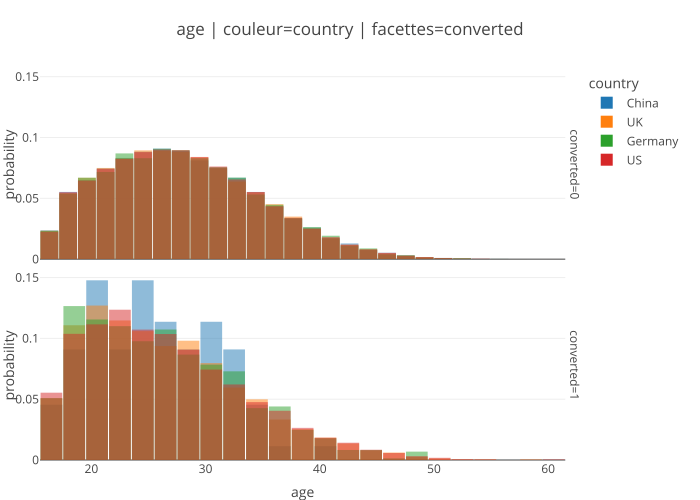

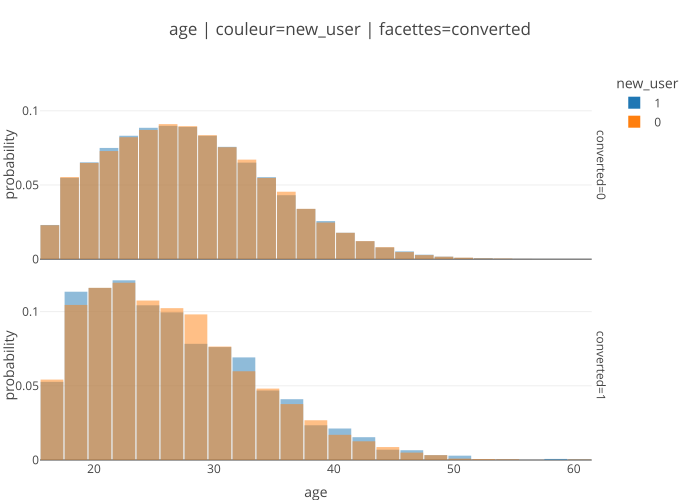

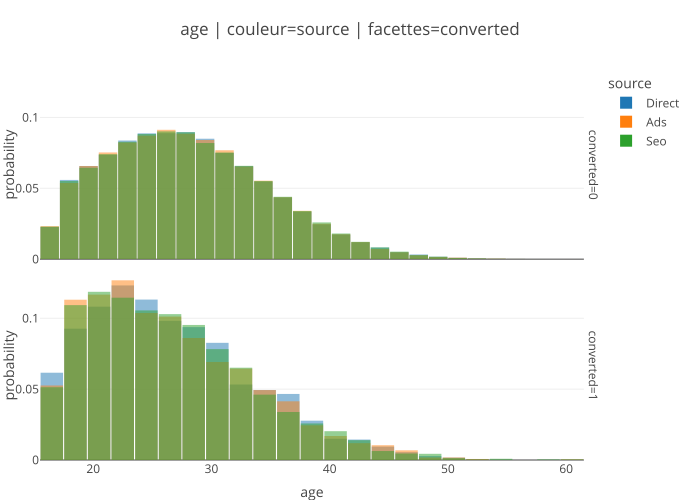

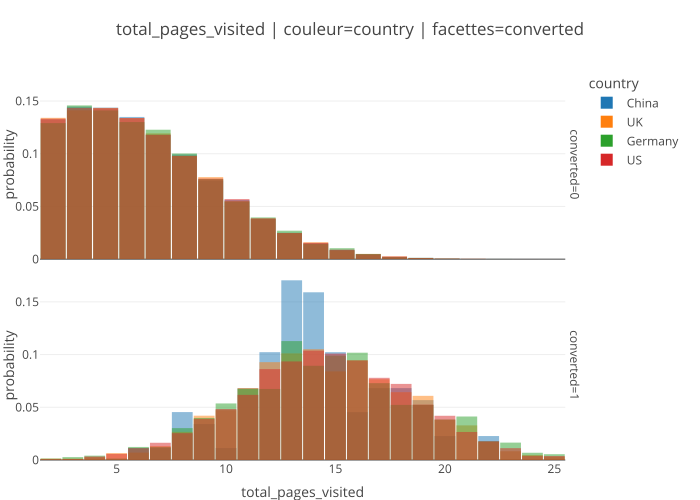

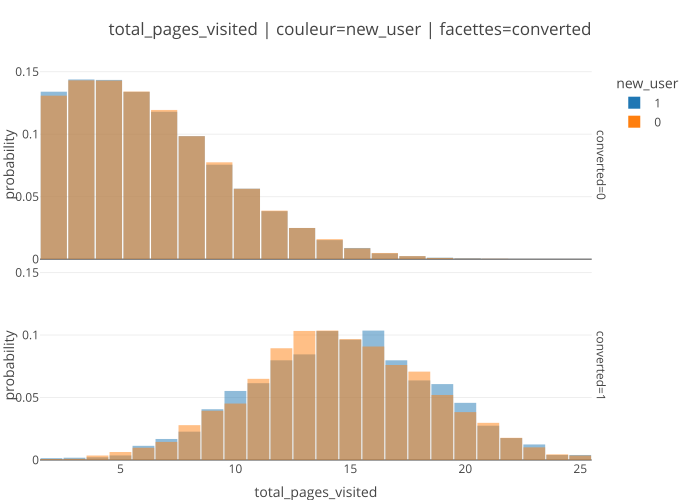

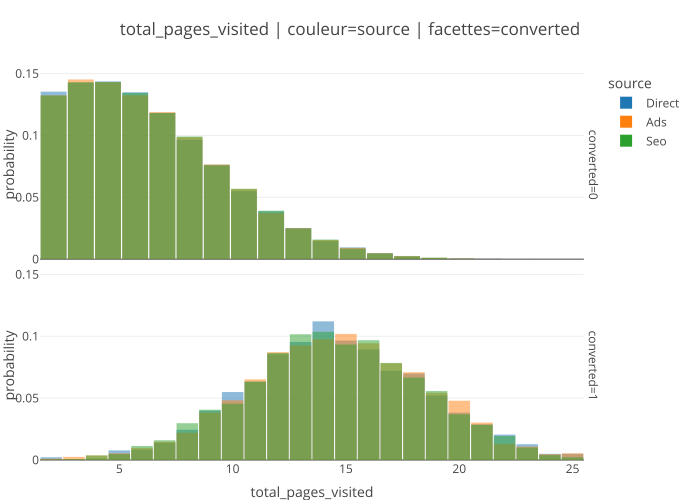

In [40]:
color_palette = [
    "#1f77b4",  # bleu
    "#ff7f0e",  # orange
    "#2ca02c",  # vert
    "#d62728",  # rouge
    "#9467bd",  # violet
    "#8c564b",  # marron
    "#e377c2",  # rose
    "#7f7f7f",  # gris
    "#bcbd22",  # jaune-vert
    "#17becf"   # turquoise
]
#color_palette = px.colors.qualitative.Set2 
for num in num_features:
    for cat in cat_features:
        fig = px.histogram(
            data_frame=data,
            x=num,
            color=cat,                 # 1 couleur par modalité de la variable catégorielle
            facet_row="converted",     # 2 subplots: converted=0 et converted=1
            histnorm="probability",
            barmode="overlay",
            opacity=0.5,
            nbins=30,
            title=f"{num} | couleur={cat} | facettes=converted",
            color_discrete_sequence=color_palette
        )
        fig.update_layout(
            legend_title_text=cat,
            bargap=0.05,
            margin=dict(l=40, r=20, t=70, b=40)
        )
        fig.update_xaxes(matches=None)  # garde l'auto-range par subplot si distributions très différentes
        fig.show()

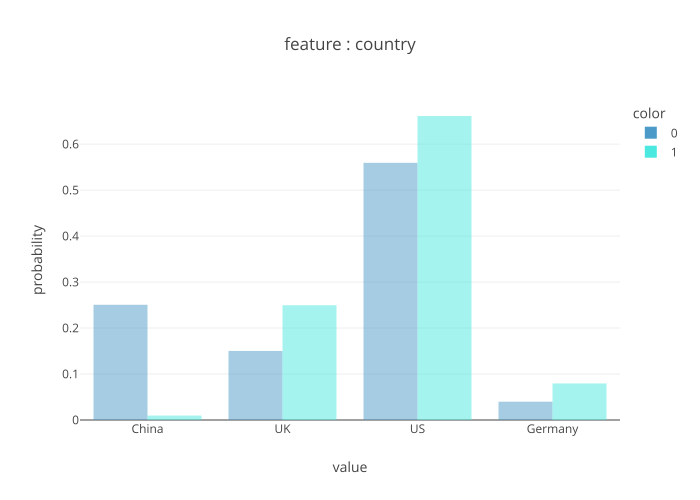

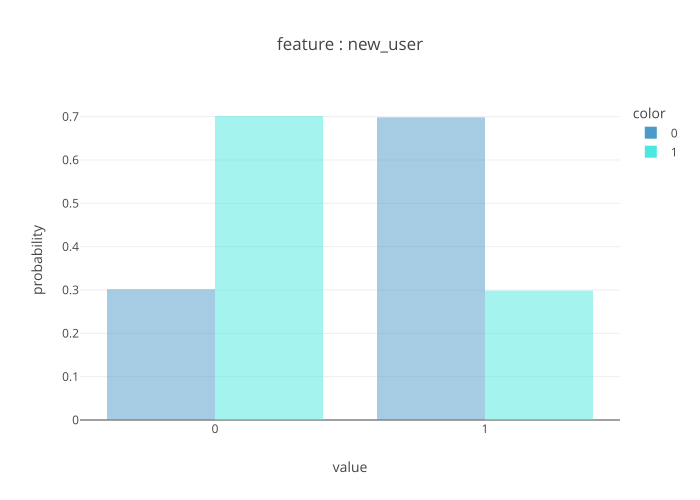

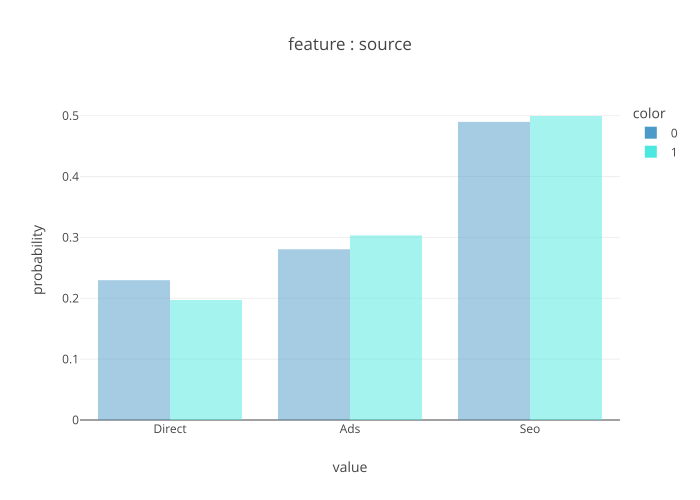

In [19]:
categorical_indices = [0,2,3]
cat_features = [features_list[i] for i in categorical_indices]
for i in range(len(cat_features)):
    fig = px.histogram(data, x=[cat_features[i]],
                       color=data['converted'].astype(str),
                       barmode = 'group',
                       title=f"feature : {cat_features[i]}",
                 histnorm='probability',
                 opacity=0.5)
    fig.show()
    
    # conversion rate in china is highly different from UK, US & Ger 

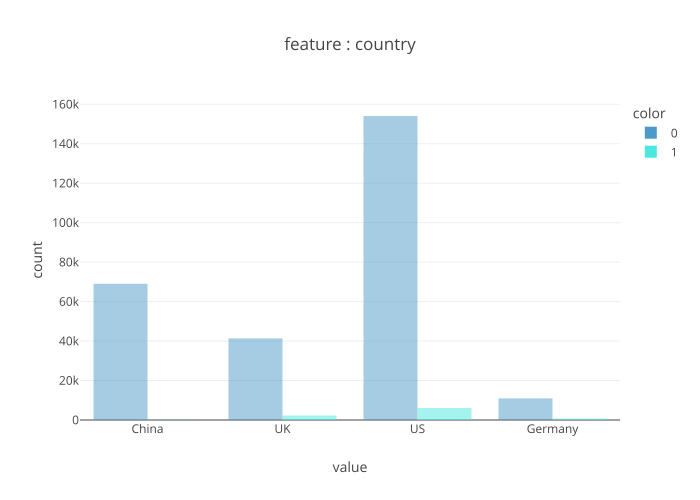

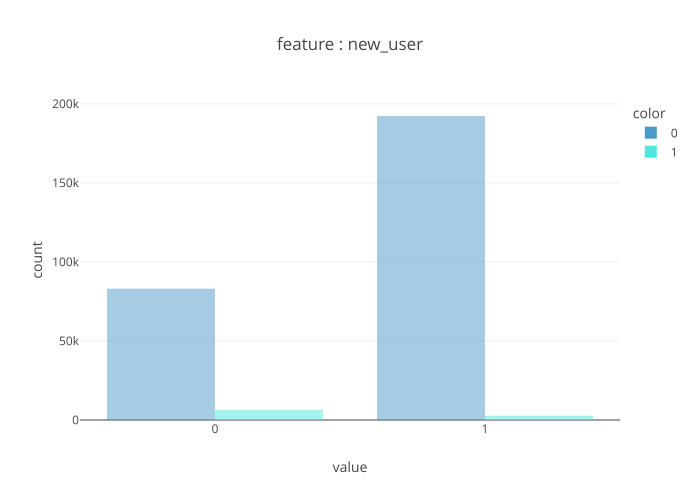

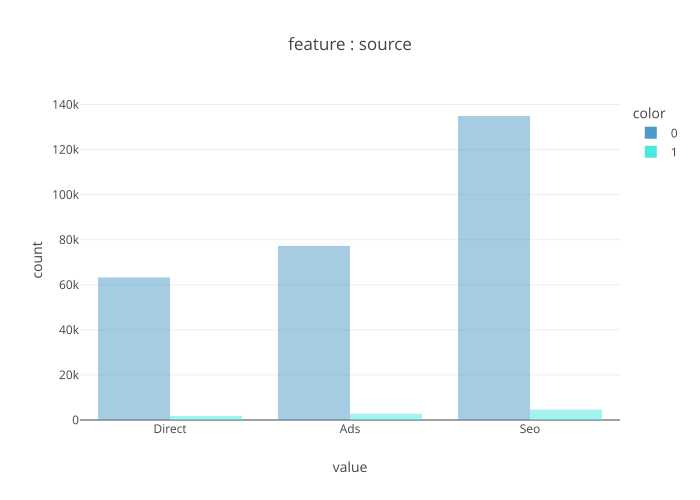

In [37]:
categorical_indices = [0,2,3]
cat_features = [features_list[i] for i in categorical_indices]
for i in range(len(cat_features)):
    fig = px.histogram(data, x=[cat_features[i]],
                       color=data['converted'].astype(str),
                       labels='converted',
                       barmode = 'group',
                       title=f"feature : {cat_features[i]}",
                 #histnorm='probability',
                 opacity=0.5)
    fig.show()

<Figure size 640x480 with 0 Axes>

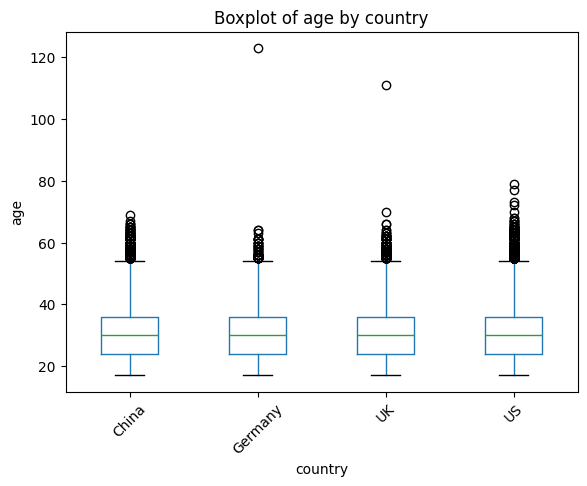

<Figure size 640x480 with 0 Axes>

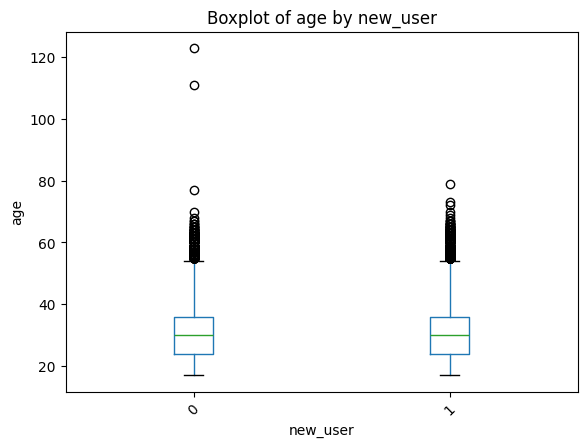

<Figure size 640x480 with 0 Axes>

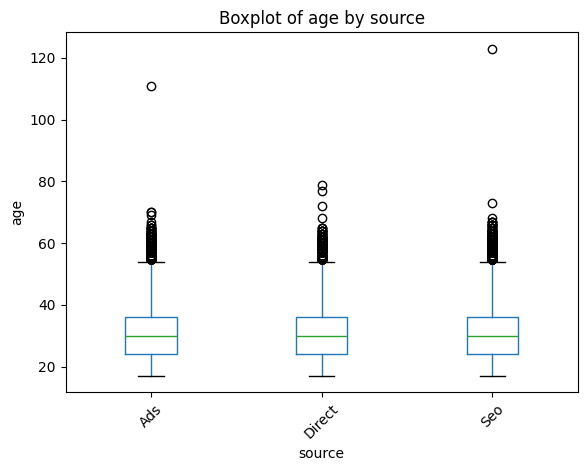

<Figure size 640x480 with 0 Axes>

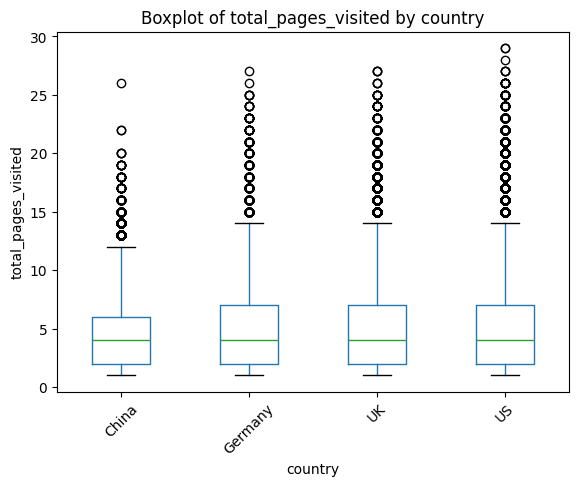

<Figure size 640x480 with 0 Axes>

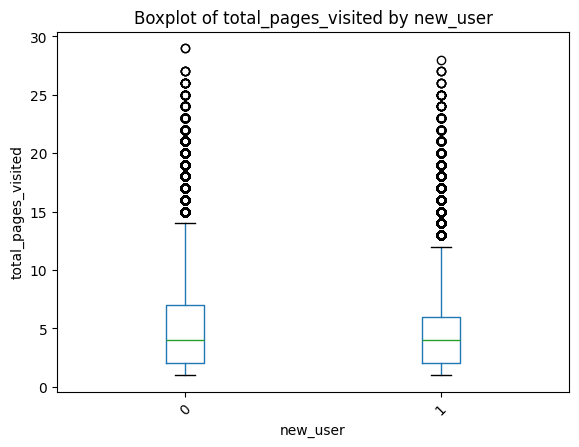

<Figure size 640x480 with 0 Axes>

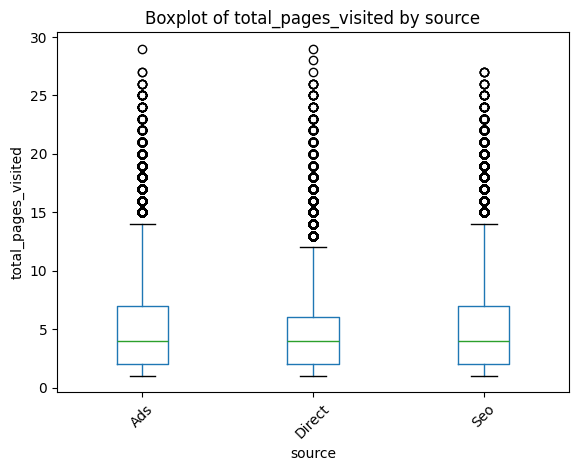

In [22]:
for i in numeric_indices:
    for j in categorical_indices:
        plt.figure()
        data.boxplot(column=features_list[i], by=features_list[j], grid=False)
        plt.title(f'Boxplot of {features_list[i]} by {features_list[j]}')
        plt.suptitle('')
        plt.xlabel(features_list[j])
        plt.ylabel(features_list[i])
        plt.xticks(rotation=45)
        plt.show()

## synthesis EDA : 
* outliers : 
  * age > 75
  * 

# Make your model

## Choose variables to use in the model, and create train and test sets
**From the EDA, we know that the most useful feature is total_pages_visited. Let's create a baseline model by using at first only this feature : in the next cells, we'll make preprocessings and train a simple (univariate) logistic regression.**

In [ ]:
data_sample.columns

Index(['country', 'age', 'new_user', 'source', 'total_pages_visited',
       'converted'],
      dtype='object')

In [41]:
"""
# scenar 0 : basic
features_list = ['total_pages_visited']
numeric_indices = [0]
categorical_indices = []
"""
# scenar 1
"""features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]"""

# scen 2 : remove 'age'
"""features_list = ['country', 'new_user', 'source','total_pages_visited']
numeric_indices = [3]
categorical_indices = [0,1,2]"""

# scen 3 : ttes col + logistic + gridsearch 
"""features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]
"""
# scen 4 to 6 : arbre random forest :
# features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
# numeric_indices = [1,4]
# categorical_indices = [0,2,3]
 
 
# scen 7&8 : arbre random forest : et red features 
# features_list = ['age', 'new_user', 'total_pages_visited']
# numeric_indices = [0,2]
# categorical_indices = [1]

# scen 9 : arbre random forest :
features_list = ['country', 'age', 'new_user', 'source','total_pages_visited']
numeric_indices = [1,4]
categorical_indices = [0,2,3]  



target_variable = 'converted'

In [44]:
X0 = data.loc[:, features_list]
Y0 = data.loc[:, target_variable]

print('Explanatory variables : ', X0.columns)
print()

Explanatory variables :  Index(['country', 'age', 'new_user', 'source', 'total_pages_visited'], dtype='object')



In [45]:
# Divide dataset Train set & Test set 
print("Dividing into train and test sets...")
X_train0, X_test0, Y_train0, Y_test0 = train_test_split(X0, Y0, test_size=0.1, random_state=0,stratify=Y0)
print("...Done.")
print()

Dividing into train and test sets...
...Done.



## Training pipeline

In [46]:
# Put here all the preprocessings
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline

print("Encoding categorical features and standardizing numerical features...")

featureencoder = StandardScaler()
cat_encoder = OneHotEncoder()

numeric_transformer = Pipeline(steps=[
    ('scaler', StandardScaler()) # pour normaliser les variables
])

# Création du pipeline pour les variables catégorielles
#categorical_features = [0] # Positions des colonnes catégorielles dans X
categorical_transformer = Pipeline(steps=[
    ('encoder', OneHotEncoder(drop='if_binary', sparse_output=False))
])


preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_indices),
        ('cat', categorical_transformer, categorical_indices)
    ],
    remainder='passthrough')


# scen 0 : 
# X_train = featureencoder.fit_transform(X_train)

# Apply StandardScaler to X
X_train = preprocessor.fit_transform(X_train0)
Y_train = Y_train0

print("...Done")
print(X_train[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[-0.55093066 -0.56081936  1.          0.          0.          0.
   1.          0.          0.          1.        ]
 [-0.42985981  0.93796149  0.          0.          0.          1.
   1.          0.          0.          1.        ]
 [ 1.50727379  0.03869298  0.          0.          0.          1.
   0.          0.          0.          1.        ]
 [ 0.17549444  0.03869298  0.          0.          0.          1.
   0.          0.          0.          1.        ]
 [-0.06664726  0.63820532  0.          0.          0.          1.
   1.          0.          0.          1.        ]]


In [57]:
from sklearn.linear_model import RidgeClassifier
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.ensemble import RandomForestClassifier
from sklearn.ensemble import (
    BaggingClassifier,
    AdaBoostClassifier,
    GradientBoostingClassifier,
    VotingClassifier,
    StackingClassifier,
)
from sklearn.tree import DecisionTreeClassifier


# Train model
print("Train model...")
#classifier = LogisticRegression(penalty='l2',solver = 'lbfgs',max_iter=1000) # 
#classifier = LogisticRegression() # 

#classifier.fit(X_train, Y_train)

# Définition du modèle de base
log_reg = LogisticRegression(max_iter=1000)
param_grid = {
    'penalty': ['l1', 'l2'],          # types de régularisation à tester
    'solver': ['liblinear', 'saga'],  # solveurs compatibles avec l1 et l2
    'C': [0.01, 0.1, 1, 10, 100]     # inverse de la force de régularisation
}
# Scen 6 & 6b :
rdf = RandomForestClassifier()
# Définition de la grille des hyperparamètres à tester
{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 64, 'n_estimators': 30}
params_rdf = {
    "max_depth": [7,10,15],
    "min_samples_leaf": [1, 2, 5],
    "min_samples_split": [16,32,64],
    "n_estimators": [15,20,30],
    'criterion':['gini','entropy']
}
grid_search = GridSearchCV(
    rdf, param_grid=params_rdf, cv=5,
    verbose=1
)  # cv : the number of folds to be used for CV

# scen 3 : Création de l'objet GridSearchCV
# grid_search = GridSearchCV(estimator=classifier,
#                            param_grid=param_grid,
#                            cv=5,              # validation croisée 5 folds
#                            scoring='accuracy', # critère d'évaluation
#                            n_jobs=-1)          # parallélisation
# Scen 8 bagging & log reg 
# model = BaggingClassifier(estimator=log_reg)

# # Grid of values to be tested
# params = {
#     "estimator__C": [
#         0.01,0.05,0.1,0.5,],  # base_estimator__ prefix because C is a parameter from LogisticRegression!
#     "n_estimators": [
#         5,10,20,30,],  # n_estimators is a hyperparameter of the ensemble method
# }
# grid_search = GridSearchCV(
#     model, param_grid=params, cv=3,
#     verbose=1
# )  # cv : the number of folds to be used for CV


# # scen10 : DTC + bagging
# decision_tree = DecisionTreeClassifier()
# model = BaggingClassifier(estimator=decision_tree)

# # Grid of values to be tested
# params = {
#     "estimator__max_depth": [1, 2, 3],
#     "estimator__min_samples_leaf": [1, 2, 3],
#     "estimator__min_samples_split": [2, 3, 4],
#     "n_estimators": [2, 4, 6, 8, 10],
# } 
# grid_search = GridSearchCV(
#     model, param_grid=params, cv=3,
#     verbose=1)  # cv : the number of folds to be used for CV

# Entraînement sur les données d'entraînement
print("Lancement du GridSearchCV...")
grid_search.fit(X_train, Y_train)
print("...Terminé.")
print("...Done.")
print("Best hyperparameters : ", grid_search.best_params_)


Train model...
Lancement du GridSearchCV...
Fitting 5 folds for each of 162 candidates, totalling 810 fits
...Terminé.
...Done.
Best hyperparameters :  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 64, 'n_estimators': 30}


In [58]:
print("Best hyperparameters : ", grid_search.best_params_)

Best hyperparameters :  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 64, 'n_estimators': 30}


In [49]:
classifier2 = grid_search.best_estimator_


In [59]:
# Predictions on training set
print("Predictions on training set...")
Y_train_pred = classifier2.predict(X_train)
print("...Done.")
print(Y_train_pred)
print()

Predictions on training set...
...Done.
[0 0 0 ... 0 0 0]



## Test pipeline

In [60]:
# Use X_test, and the same preprocessings as in training pipeline, 
# but call "transform()" instead of "fit_transform" methods (see example below)

print("Encoding categorical features and standardizing numerical features...")

X_test = preprocessor.transform(X_test0)
Y_test = Y_test0
print("...Done")
print(X_test[0:5,:])

Encoding categorical features and standardizing numerical features...
...Done
[[ 1.38620294  0.03869298  0.          0.          0.          1.
   1.          0.          0.          1.        ]
 [-0.79307236 -1.1603317   0.          0.          0.          1.
   1.          0.          0.          1.        ]
 [-0.30878896  0.03869298  0.          0.          1.          0.
   1.          1.          0.          0.        ]
 [-1.27735576  0.63820532  1.          0.          0.          0.
   1.          0.          0.          1.        ]
 [ 0.90191954  0.33844915  0.          0.          0.          1.
   1.          0.          0.          1.        ]]


In [61]:
# Predictions on test set
print("Predictions on test set...")
Y_test_pred = classifier2.predict(X_test)
print("...Done.")
print(Y_test_pred)
print()

Predictions on test set...
...Done.
[0 0 0 ... 0 0 0]



## Performance assessment

In [ ]:
# WARNING : Use the same score as the one that will be used by Kaggle !
# Here, the f1-score will be used to assess the performances on the leaderboard
print(grid_search.best_params_)
print(f"f1-score on train set : {f1_score(Y_train, Y_train_pred):2.4f}")
print(f"f1-score on test set :  {f1_score(Y_test, Y_test_pred):2.4f}")

{'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 64, 'n_estimators': 30}
f1-score on train set : 0.7317
f1-score on test set :  0.7352


: 

In [63]:
# You can also check more performance metrics to better understand what your model is doing
print("Confusion matrix on train set : ")
print(confusion_matrix(Y_train, Y_train_pred))
print()
print("Confusion matrix on test set : ")
print(confusion_matrix(Y_test, Y_test_pred))
print()

Confusion matrix on train set : 
[[246980    876]
 [  2980   5258]]

Confusion matrix on test set : 
[[27452    88]
 [  332   583]]



scen 0 : 
Scen_nr        cols        model       F1_train    F1_test 
0              nb_pages    Logistic    0.69
Confusion matrix on train set : 
[[246817   1082]
 [  3280   4943]]

Confusion matrix on test set : 
[[27384   117]
 [  371   586]]


1              all         logistic    0.76        0.757   
Confusion matrix on train set : 
[[246946    953]
 [  2558   5665]]

Confusion matrix on test set : 
[[27394   107]
 [  309   648]]

2           suppr age       logistic    0.74     
3           all             log+gridsearch  0.76497     0.756851
4           all             rdmF + gs {'criterion': 'gini',
 'max_depth': 10,
 'min_samples_split': 8,
 'n_estimators': 20}        0.7780  0.75635
5           all             rdf+gs {'criterion': 'entropy',
 'max_depth': 10,
 'min_samples_split': 32,
 'n_estimators': 20}
0.7727668699323192
f1-score on test set :  0.76096997 

6 ***       all             rdf+gs  {'criterion': 'entropy', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 64, 'n_estimators': 30}
f1-score on train set :  0.7672558639693527   ***
f1-score on test set :  0.7628985507246376

6b          all+Rm_outl   rdf+gs

7           ['age', 'new_user', 'total_pages_visited']  rdf+gs 
f1 0.74  bof 

8           idem    bagging+ logreg     0.7411  0.7426

9:          all     bagging+ logreg     {'estimator__C': 0.5, 'n_estimators': 10}
f1-score on train set :  0.7638063439065108
f1-score on test set :  0.7553324968632371 

10          all+Rm_outl DTC + bagging  {'estimator__max_depth': 3, 'estimator__min_samples_leaf': 1, 'estimator__min_samples_split': 3, 'n_estimators': 2}
f1-score on train set : 0.7317
f1-score on test set :  0.7352

11 




**Our baseline model reaches a f1-score of almost 70%. Now, feel free to refine your model and try to beat this score ! 🚀🚀**

# Train best classifier on all data and use it to make predictions on X_without_labels
**Before making predictions on the file conversion_data_test.csv, let's train our model on ALL the data that was in conversion_data_train.csv. Sometimes, this allows to make tiny improvements in the score because we're using more examples to train the model.**

In [ ]:
# Concatenate our train and test set to train your best classifier on all data with labels
X = np.append(X_train,X_test,axis=0)
Y = np.append(Y_train,Y_test)

classifier2.fit(X,Y)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",20
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'entropy'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",7
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",64
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",5
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

In [ ]:
# Read data without labels
data_without_labels = pd.read_csv('conversion_data_test.csv')
print('Prediction set (without labels) :', data_without_labels.shape)

# Warning : check consistency of features_list (must be the same than the features 
# used by your best classifier)
features_list = ['country', 'age','new_user', 'source','total_pages_visited']
X_without_labels = data_without_labels.loc[:, features_list]

# Convert pandas DataFrames to arrays before using scikit-learn
print("Convert pandas DataFrames to arrays...")
X_without_labels = X_without_labels.values
print("...Done")

print(X_without_labels[0:5,:])

Prediction set (without labels) : (31620, 5)
Convert pandas DataFrames to arrays...
...Done
[['UK' 28 0 'Seo' 16]
 ['UK' 22 1 'Direct' 5]
 ['China' 32 1 'Seo' 1]
 ['US' 32 1 'Ads' 6]
 ['China' 25 0 'Seo' 3]]


In [ ]:
# WARNING : PUT HERE THE SAME PREPROCESSING AS FOR YOUR TEST SET
# CHECK YOU ARE USING X_without_labels
print("Encoding categorical features and standardizing numerical features...")

X_without_labels = preprocessor.transform(X_without_labels)
print("...Done")
print(X_without_labels[0:5,:])

Encoding categorical features and standardizing numerical features...


ValueError: X has 5 features, but ColumnTransformer is expecting 3 features as input.

In [ ]:
# Make predictions and dump to file
# WARNING : MAKE SURE THE FILE IS A CSV WITH ONE COLUMN NAMED 'converted' AND NO INDEX !
# WARNING : FILE NAME MUST HAVE FORMAT 'conversion_data_test_predictions_[name].csv'
# where [name] is the name of your team/model separated by a '-'
# For example : [name] = AURELIE-model1
data = {
    'converted': classifier2.predict(X_without_labels)
}

Y_predictions = pd.DataFrame(columns=['converted'],data=data)
Y_predictions.to_csv('conversion_data_test_predictions_Cyril_Braguy_scen6.csv', index=False)


## Analyzing the coefficients and interpreting the result
**In this template, we just trained a model with only one feature (total_pages_visited), so there's no analysis to be done about the feature importance 🤔**

**Once you've included more features in your model, please take some time to analyze the model's parameters and try to find some lever for action to improve the newsletter's conversion rate 😎😎**